Importing libraries


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, BatchNormalization, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix

In [3]:
img_size = 224
batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    '/Users/ahbiswas/Documents/Data_sets/brain_tumer/Training',
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical'
)

test_data = test_datagen.flow_from_directory(
    '/Users/ahbiswas/Documents/Data_sets/brain_tumer/Testing',
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


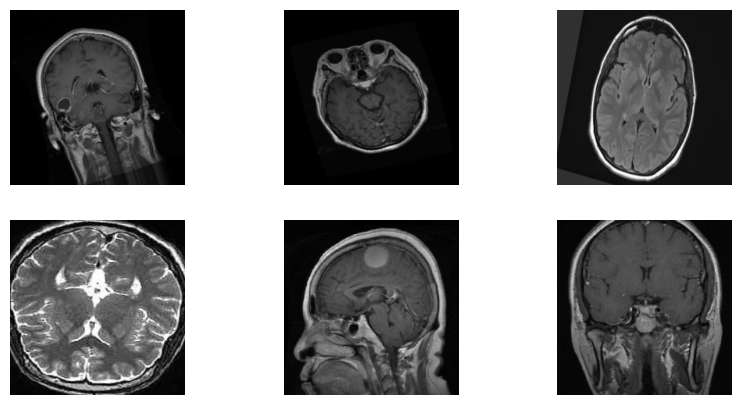

In [4]:
images, labels = next(train_data)

plt.figure(figsize=(10,5))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i])
    plt.axis('off')
plt.show()

In [ ]:
model = Sequential()

# Block 1
model.add(Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)))
model.add(MaxPooling2D(2,2))
model.add(BatchNormalization())

# Block 2
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(BatchNormalization())

# Block 3
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(BatchNormalization())

# Fully Connected
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(4, activation='softmax'))  # 4 classes

/Users/ahbiswas/Documents/DL_project/CNN/assi1_cnn_brain/.venv/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=25,
    callbacks=[early_stop]
)

Epoch 1/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 106s 596ms/step - accuracy: 0.4263 - loss: 2.6535 - val_accuracy: 0.2500 - val_loss: 10.4107
Epoch 2/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 130s 742ms/step - accuracy: 0.4057 - loss: 1.4324 - val_accuracy: 0.3887 - val_loss: 1.2792
Epoch 3/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 143s 816ms/step - accuracy: 0.4609 - loss: 1.2011 - val_accuracy: 0.3794 - val_loss: 1.2912
Epoch 4/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 324s 601ms/step - accuracy: 0.4684 - loss: 1.1220 - val_accuracy: 0.5581 - val_loss: 1.4003
Epoch 5/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 135s 773ms/step - accuracy: 0.4761 - loss: 1.0943 - val_accuracy: 0.5713 - val_loss: 2.6995
Epoch 6/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 134s 762ms/step - accuracy: 0.4921 - loss: 1.0995 - val_accuracy: 0.6144 - val_loss: 1.4523
Epoch 7/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 143s 819ms/step - accuracy: 0.4970 - loss: 1.1003 - val_accuracy: 0.5231 - val_loss: 2.5402


In [8]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)

50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 213ms/step - accuracy: 0.3887 - loss: 1.2792
Test Accuracy: 0.38874998688697815


In [9]:
preds = model.predict(test_data)
y_pred = np.argmax(preds, axis=1)

cm = confusion_matrix(test_data.classes, y_pred)
print(cm)

print(classification_report(test_data.classes, y_pred))

50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 239ms/step
[[106   9   5 280]
 [ 44  40   2 314]
 [  5  21  76 298]
 [  0   0   0 400]]
              precision    recall  f1-score   support

           0       0.68      0.27      0.38       400
           1       0.57      0.10      0.17       400
           2       0.92      0.19      0.31       400
           3       0.31      1.00      0.47       400

    accuracy                           0.39      1600
   macro avg       0.62      0.39      0.33      1600
weighted avg       0.62      0.39      0.33      1600



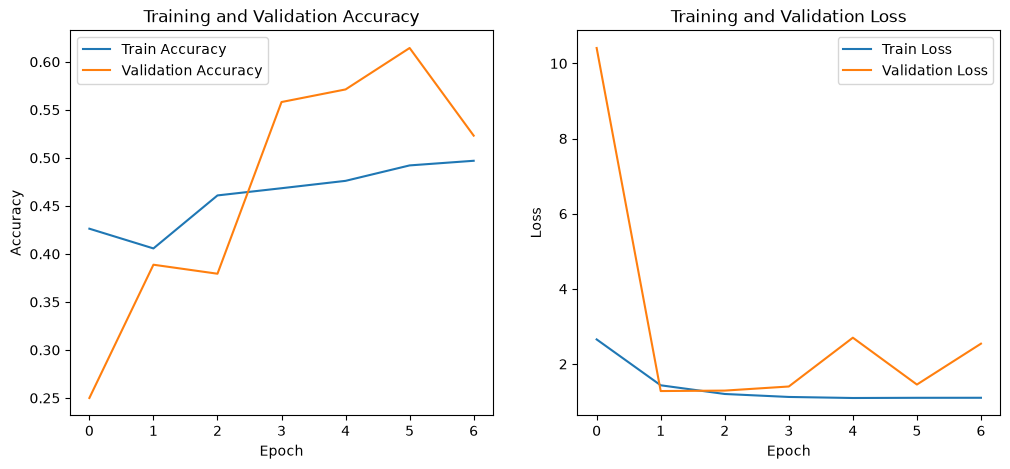

In [10]:
# plot training and validation accuracy and loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()